# SHAP, counterfactual and sensitivity analysis — churn model v1.0.0 (logistic regression)

**Project:** Retail Analytics Decision Support Platform (Online Retail II) · **Task:** 90-day customer churn (the 90-day window is **PROPOSED**, pending Marketing agreement)

This notebook is deliberately thin: all logic lives in `src/churn_model/explain.py` so that the notebook, the report and the Model Card use the same code. It **recomputes** every number and asserts that it matches `reports/model/explainability_results.json`, which is what the report quotes. It does **not** open new MLflow runs; the single logged explainability run is in the MLflow evidence.

Reading rules: SHAP values here are on the **log-odds** scale for a linear model with an independent background, so they describe how the *model* uses features, not what *causes* churn. Counterfactuals are *model-based what-ifs about recorded behaviour*, not causal advice. No protected attributes exist in the data; none are used or varied.

In [1]:
import json, numpy as np, pandas as pd, matplotlib
matplotlib.use("Agg")
from pathlib import Path
from IPython.display import Image, display
from churn_model import explain as X, dataset as D, tracking
ROOT = tracking.ROOT; FIG = ROOT/"reports/model/figures"
stored = json.loads((ROOT/"reports/model/explainability_results.json").read_text())
cfg, pipe, thr, df, m, names = X.load()
te = df[m["test"]].reset_index(drop=True)
pr = pd.read_parquet(ROOT/"data/modeling/test_predictions.parquet")
assert (pr.customer_key.values==te.customer_key.values).all()
te["p"]=pr.p.values; te["pred"]=pr.pred.values
assert np.allclose(te.p, pipe.predict_proba(te[D.FEATURES])[:,1])
print(f"test rows={len(te)}  threshold={thr:.6f}  prevalence={te.churn.mean():.3f}")

/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


test rows=5534  threshold=0.313903  prevalence=0.418


## 1. Global explanation
Mean |SHAP| over 2,000 random **test** rows (background: 500 random **training** rows, seed fixed).

In [2]:
g, ex, sv, idx, raw = X.global_shap(pipe, thr, df, m, names)
imp = pd.Series(g["mean_abs_shap"]).round(4)
assert imp.round(4).to_dict()==pd.Series(stored["global_shap"]["mean_abs_shap"]).round(4).to_dict()
print("expected value (log-odds):", round(g["expected_value"],4)); imp.to_frame("mean |SHAP| (log-odds)").head(10)

expected value (log-odds): -0.0427


,mean |SHAP| (log-odds)
Invoices (all history),0.8181
Days since first purchase,0.3998
Revenue (all history),0.3652
"Invoices, last 90d",0.3080
"Distinct products, 180d",0.2882
Distinct products (all),0.2348
"Revenue, last 90d",0.1727
Days since last purchase,0.1228
"Invoices, 91-180d ago",0.1197
Recency / mean gap,0.1175


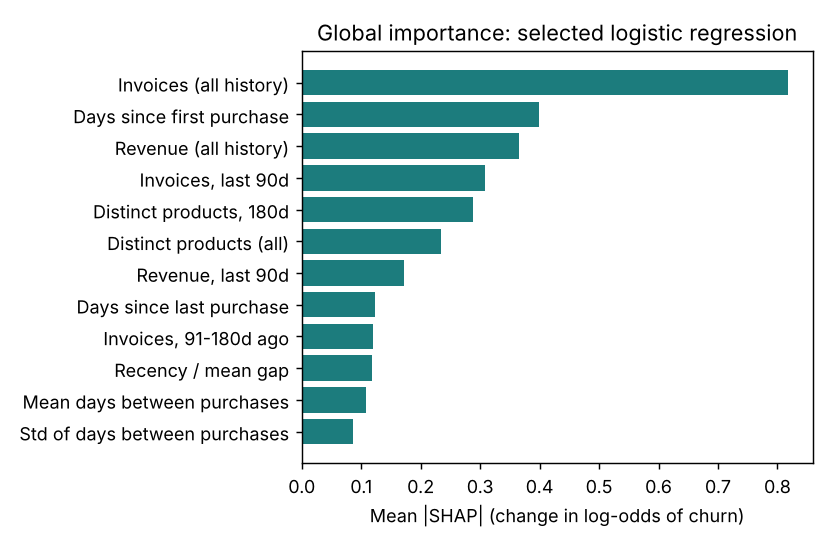

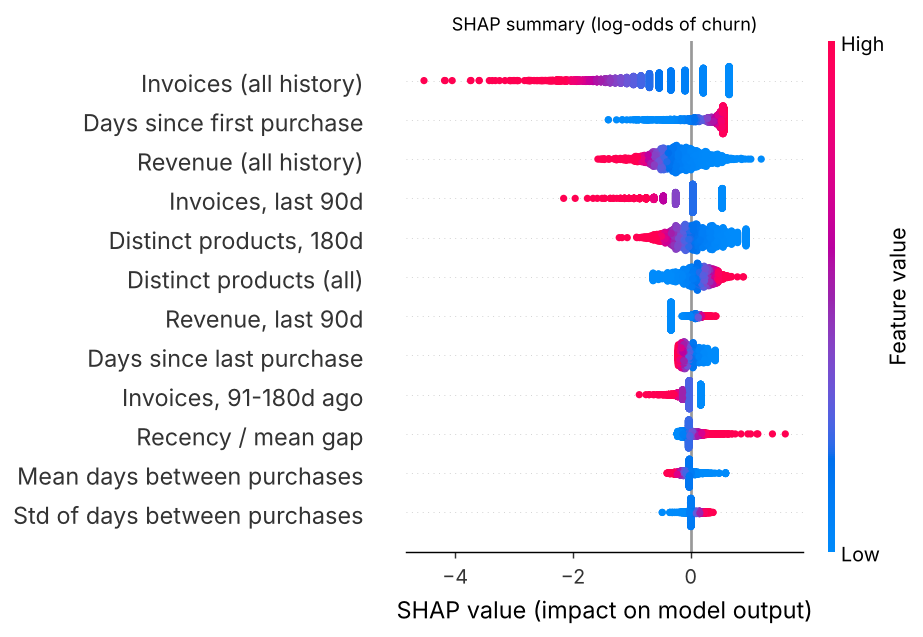

In [3]:
display(Image(str(FIG/'shap_global_bar.png'))); display(Image(str(FIG/'shap_summary_beeswarm.png')))

**Grouped importance** (sum of mean |SHAP| by business concept) and the **direction** of each feature's effect (Spearman between feature value and SHAP; −1 = higher value lowers churn risk).

Purchase frequency     1.037
Tenure                 0.400
Spend                  0.328
Product breadth        0.191
Recency                0.117
Purchase regularity    0.078
Cancellations          0.053

Days since last purchase        -1.0
Days since first purchase        1.0
Invoices (all history)          -1.0
Invoices, last 30d               1.0
Invoices, last 90d              -1.0
Invoices, 91-180d ago           -1.0
Only one purchase so far         1.0
Revenue (all history)           -1.0
Revenue, last 90d                1.0
Revenue, last 180d               1.0
Distinct products (all)          1.0
Distinct products, 180d         -1.0
Avg units per invoice            1.0
Mean days between purchases     -1.0
Std of days between purchases    1.0
Recency / mean gap               1.0
Cancellation invoices           -1.0
Cancellation share              -1.0


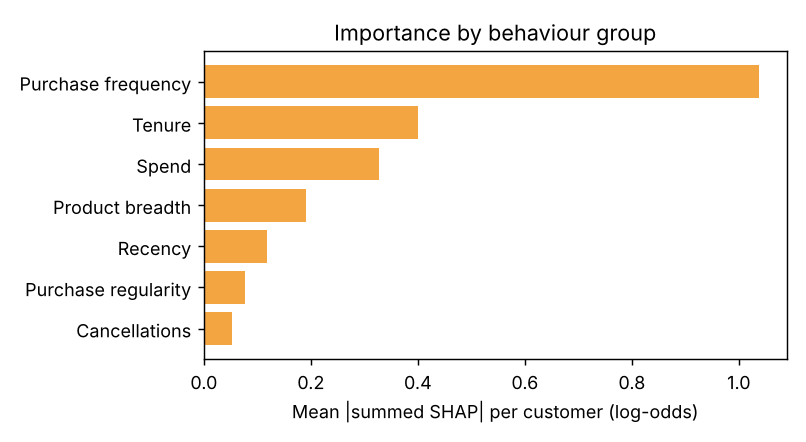

In [4]:
print(pd.Series(g["group_importance"]).round(3).to_string()); print()
print(pd.Series(g["direction_spearman"]).round(2).to_string())
display(Image(str(FIG/'shap_group_bar.png')))

### Cross-check with a second model class
A LightGBM model fitted with the same training data gives a different importance ranking (Spearman ≈ 0.58, top-5 overlap 3 of 5). Purchase history volume and revenue dominate in both, but the *ordering of secondary features differs*, so feature rankings should be read as indicative, not exact. The deployed model is the logistic regression.

In [5]:
lg = X.compare_lightgbm(df, m, names, idx)
common=[n for n in imp.index if n in lg.index]
from scipy.stats import spearmanr
rho=spearmanr(imp[common], lg[common])[0]; print("Spearman rank agreement logreg vs LightGBM:", round(rho,3))
assert abs(rho-stored["shap_model_agreement"]["spearman_rank_logreg_vs_lightgbm"])<1e-6
pd.DataFrame({"logreg":imp, "lightgbm":lg.round(4)}).head(8)

Spearman rank agreement logreg vs LightGBM: 0.581


/usr/local/lib/python3.13/site-packages/shap/explainers/_tree.py:578: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


,logreg,lightgbm
Avg units per invoice,0.0049,0.0119
Cancellation invoices,0.0227,0.0109
Cancellation share,0.0316,0.0361
Days since first purchase,0.3998,0.0819
Days since last purchase,0.1228,0.0420
Distinct products (all),0.2348,0.0277
"Distinct products, 180d",0.2882,0.0685
Invoices (all history),0.8181,0.4571


## 2. Local explanations
Five cases chosen by a **deterministic rule written before looking at them** (not hand-picked): typical true positive, typical true negative, most confident false positive, least confident false negative, nearest to the threshold.

In [6]:
cases = X.pick_cases(te, thr); print(X.pick_cases.__doc__)
loc = X.local_explanations(pipe, ex, thr, te, names, cases)
for tag,v in loc.items():
    assert abs(v["p_churn"]-stored["local"][tag]["p_churn"])<1e-9
    print(f"\n{tag}: p={v['p_churn']:.3f} actual={v['actual_churn']} flagged={v['flagged']}")
    for d in v["top_drivers"]: print(f"   {d['feature']:<28} value={d['value']:<9} SHAP={d['shap_log_odds']:+.2f}")

Documented selection rule (deterministic): A typical flagged churner (TP nearest median p of TPs); B typical retained (TN nearest median p of TNs);
C most confident false positive; D least confident false negative; E nearest to the decision threshold.



A_typical_true_positive: p=0.589 actual=1 flagged=1
   Invoices, last 90d           value=0.0       SHAP=+0.53
   Days since first purchase    value=426.0     SHAP=+0.43
   Revenue, last 90d            value=0.0       SHAP=-0.33
   Mean days between purchases  value=260.0     SHAP=-0.29

B_typical_true_negative: p=0.156 actual=0 flagged=0
   Invoices (all history)       value=11.0      SHAP=-1.28
   Revenue (all history)        value=3814.23   SHAP=-0.51
   Days since first purchase    value=500.0     SHAP=+0.49
   Distinct products, 180d      value=87.0      SHAP=-0.40

C_confident_false_positive: p=0.841 actual=0 flagged=1
   Recency / mean gap           value=40.25     SHAP=+1.22
   Invoices, last 90d           value=0.0       SHAP=+0.53
   Mean days between purchases  value=4.0       SHAP=+0.34
   Revenue, last 90d            value=0.0       SHAP=-0.33

D_missed_churner_false_negative: p=0.036 actual=1 flagged=0
   Invoices (all history)       value=31.0      SHAP=-2.34
   Revenue

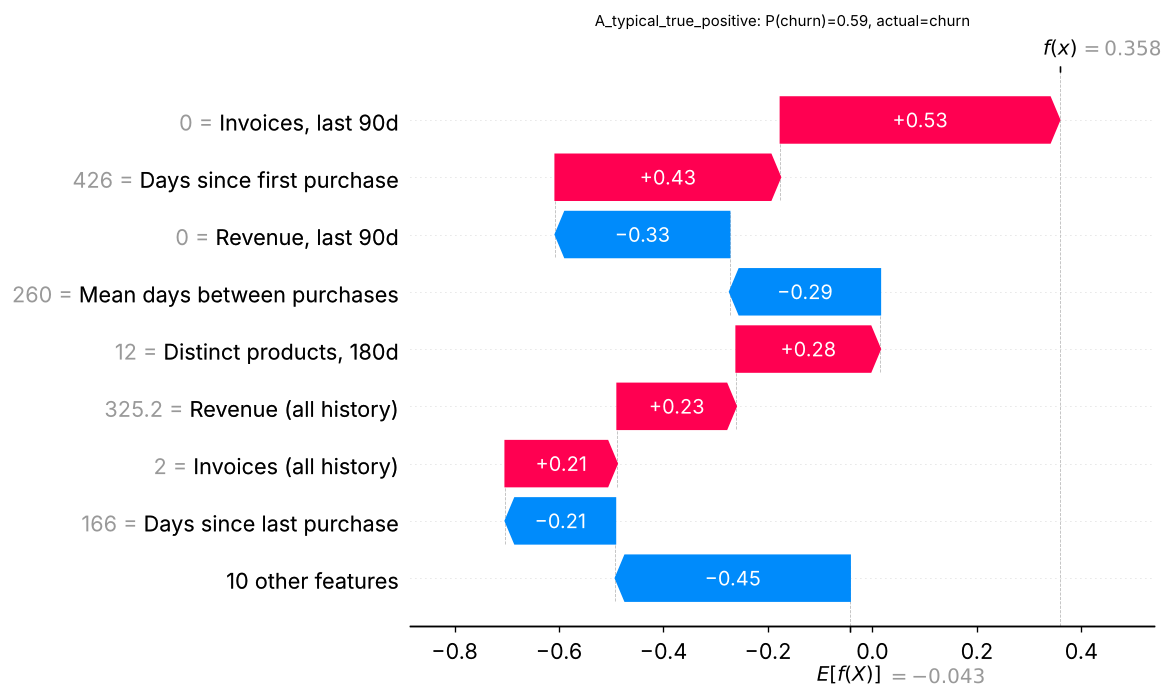

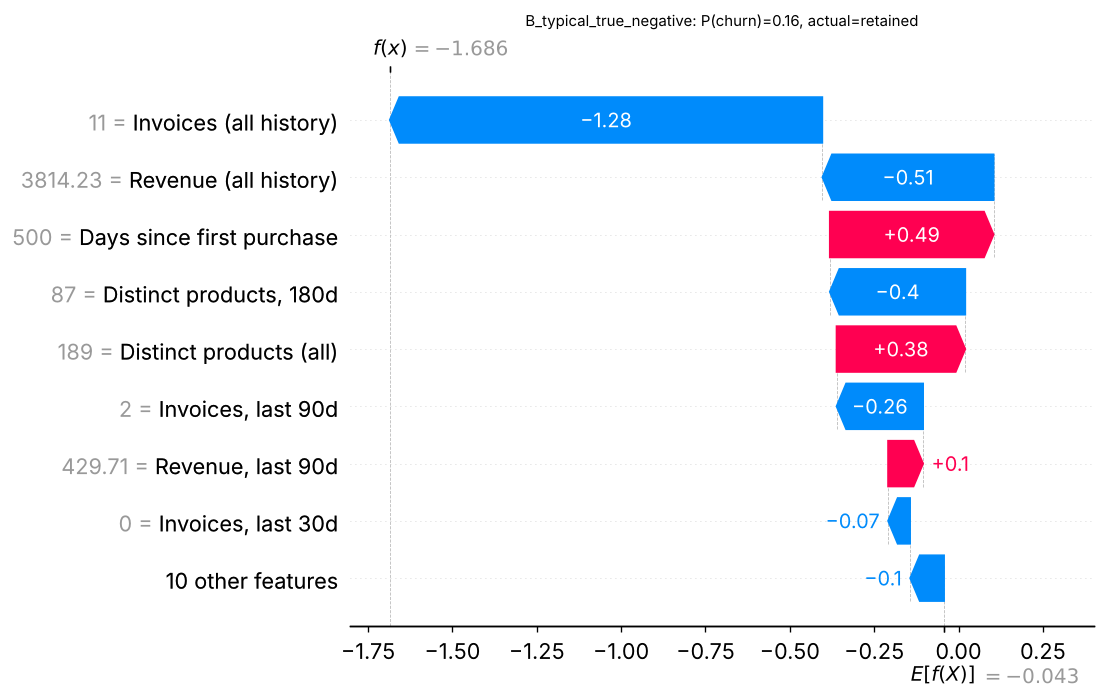

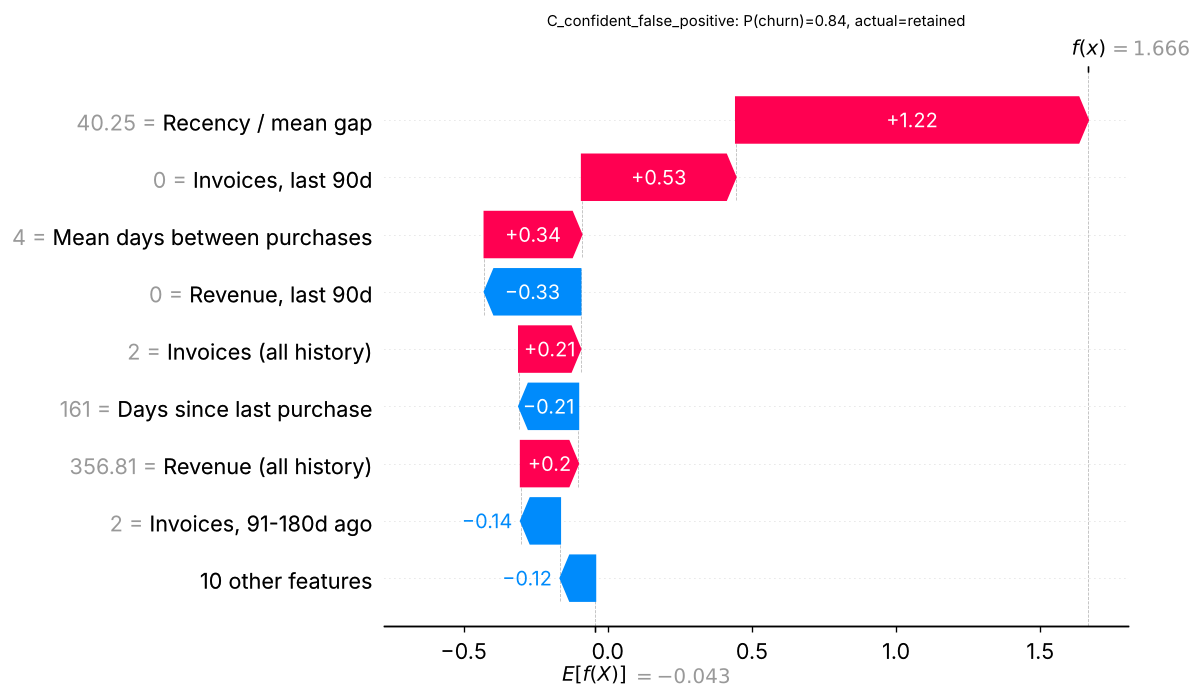

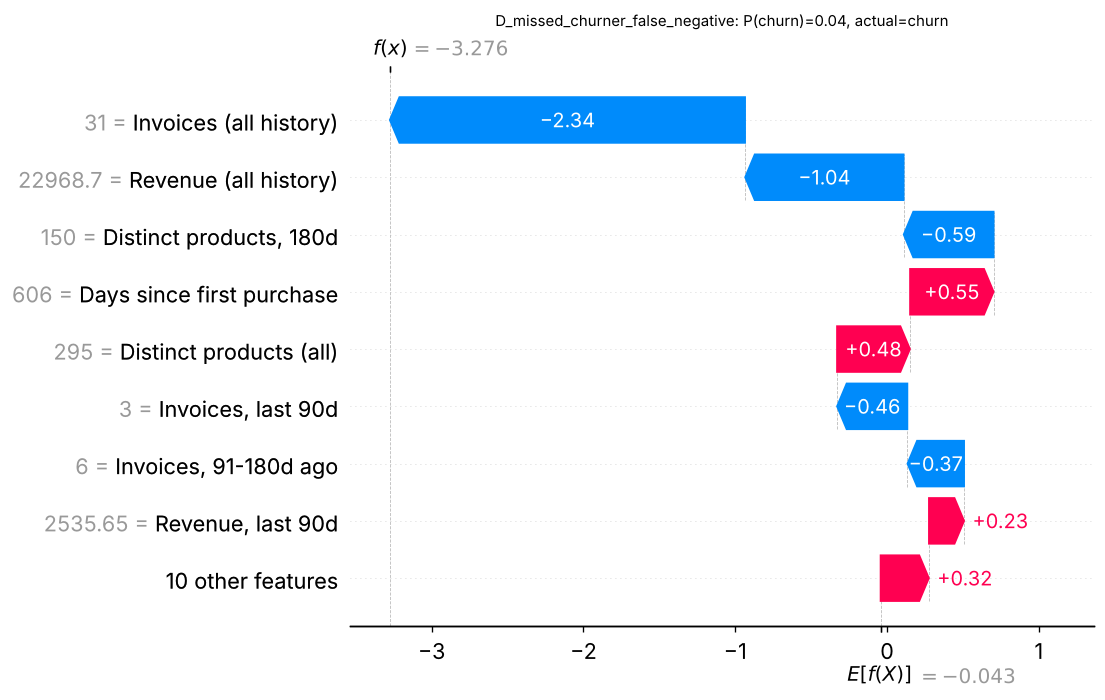

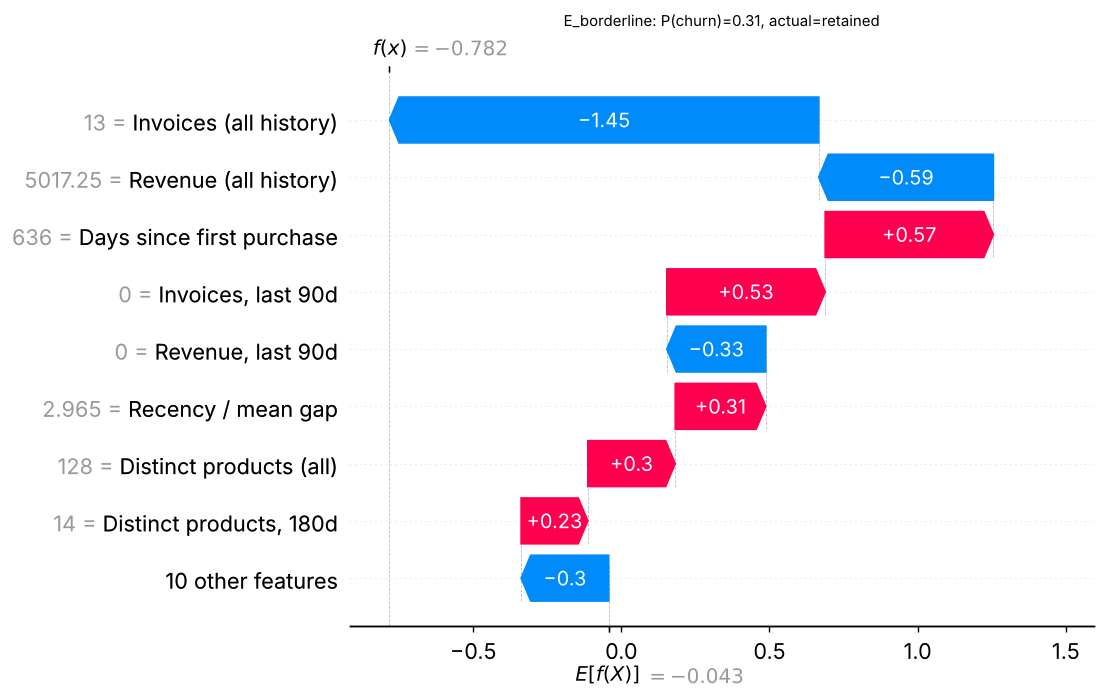

In [7]:
for f in sorted(FIG.glob('shap_local_*.png')): display(Image(str(f)))

Two cases are worth reading closely:
* **C (false positive):** `recency / mean gap = 40` — a customer who normally buys every ~4 days and has been silent for 161 days. The model is right to be worried; the customer then bought anyway. This is the irreducible uncertainty of a behavioural model.
* **D (missed churner):** 31 invoices and £22,969 revenue push the probability down to 0.036, yet the customer did not return. Strong history lowers risk on average but does not guarantee retention; high-value silent customers are exactly where a human account manager should look beyond the score.

## 3. Counterfactuals (verified, constrained)
For flagged customers we search for the **smallest change in mutable behaviour** that moves the model below the threshold. Mutable: number of additional invoices *k* (≤ 6) in the recent window and the day of the most recent purchase *r*. **Immutable (held fixed):** tenure, product breadth, gap statistics, cancellation history, country/group. Nested windows are kept consistent (30d ⊂ 90d ⊂ all-time). Every counterfactual is **re-scored through the full pipeline** before being reported.

In [8]:
cf = X.counterfactual_batch(pipe, thr, te, cases)
print(json.dumps(cf["batch"], indent=1)); print("verified reported cases:", cf["verified_reported_case_counterfactuals"], "|", cf["immutable"])
for tag,v in cf["cases"].items():
    if v.get("needed"):
        assert v["found"] and v["p1"]<thr<=v["p0"]            # verified: flips from flagged to not flagged
        print(f"{tag}: p {v['p0']:.3f} -> {v['p1']:.3f} with {v['extra_invoices']} extra invoice(s), latest purchase {v['latest_purchase_days_before_T']} day(s) before the prediction date")
    else: print(f"{tag}: not flagged (p={v['p0']:.3f}); no counterfactual needed")
assert cf["batch"]==stored["counterfactuals"]["batch"]

{
 "n_flagged_sampled": 300,
 "feasible_share": 0.9933333333333333,
 "median_extra_invoices": 3.0,
 "share_needing_1_invoice": 0.1610738255033557,
 "search_limit": "up to 6 extra invoices"
}
verified reported cases: 2/2 | tenure, product breadth, gap statistics, cancellations, country/group are held fixed
A_typical_true_positive: p 0.589 -> 0.245 with 3 extra invoice(s), latest purchase 90 day(s) before the prediction date
B_typical_true_negative: not flagged (p=0.156); no counterfactual needed
C_confident_false_positive: p 0.841 -> 0.293 with 5 extra invoice(s), latest purchase 1 day(s) before the prediction date
D_missed_churner_false_negative: not flagged (p=0.036); no counterfactual needed
E_borderline: not flagged (p=0.314); no counterfactual needed


**Interpretation limits.** These are statements about *the model's response to recorded behaviour*. They are **not** evidence that prompting an extra purchase would cause retention, and 99% 'feasibility' only shows that the model is monotone in purchase activity within the search limit — it is a property of the model, not of customers.

## 4. Sensitivity analysis
Perturbations are applied to the **test** features; the model is not refitted. ΔAUC is relative to the unperturbed test AUC; *flag flip rate* is the share of customers whose flag changes.

In [9]:
sens, auc0 = X.sensitivity(pipe, thr, te, names, ex, None)
print("baseline test AUC:", round(auc0,4))
out = sens.reset_index(); st = pd.DataFrame(stored["sensitivity"])
assert np.allclose(out.sort_values("perturbation")[["auc","flag_flip_rate"]].values, st.sort_values("perturbation")[["auc","flag_flip_rate"]].values, atol=1e-4)
out

baseline test AUC: 0.7655


,perturbation,auc,delta_auc,delta_auc_min,mean_abs_dp,flag_flip_rate,reps
0,cancellation history unavailable,0.7663,0.0008,0.0008,0.0096,0.0192,1
1,monetary noise (lognormal sigma=0.1),0.7655,0.0000,-0.0003,0.0030,0.0041,10
2,monetary noise (lognormal sigma=0.2),0.7652,-0.0003,-0.0008,0.0060,0.0080,10
3,random missingness 10% in 5 features,0.7628,-0.0027,-0.0044,0.0109,0.0141,10
4,random missingness 20% in 5 features,0.7599,-0.0056,-0.0074,0.0199,0.0268,10
5,random missingness 5% in 5 features,0.7640,-0.0015,-0.0021,0.0055,0.0071,10
6,recency shift +3 days,0.7657,0.0002,0.0002,0.0016,0.0023,1
7,recency shift +7 days,0.7658,0.0003,0.0003,0.0032,0.0043,1
8,recency shift -3 days,0.7652,-0.0003,-0.0003,0.0019,0.0023,1
9,recency shift -7 days,0.7645,-0.0010,-0.0010,0.0047,0.0067,1


**Reading:** the model is stable to monetary noise and ±7-day recency shifts (|ΔAUC| ≤ 0.001). Missing values hurt gradually (−0.006 AUC at 20% missingness in five features), and removing cancellation history costs nothing — consistent with cancellations being the weakest signals in §1. Stability under *these* perturbations says nothing about stability under a genuine change in customer behaviour (drift), which the monitoring plan handles.

## 5. Verification summary
All assertions above passed if this notebook ran top-to-bottom: global importance, local probabilities, counterfactual batch statistics and sensitivity results **match** the stored results file, and every reported counterfactual flips the pipeline's decision when re-scored.